# Análisis exploratorio de datos — House Pricing

Este notebook analiza el conjunto de datos de viviendas con el fin de comprender su estructura, calidad y relaciones antes del modelado del precio de venta (`SalePrice`).

## 1. Librerías

Importación de las librerías del ecosistema PyData utilizadas en el análisis: manipulación de datos (`numpy`, `pandas`), visualización (`matplotlib`, `seaborn`), estadística (`scipy`, `statsmodels`) y aprendizaje automático (`scikit-learn`).

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats
import statsmodels.api as sm
import sklearn

## 2. Carga de datos

Lectura de los conjuntos de entrenamiento (`train`) y prueba (`test`). La ubicación de las fuentes se define en `DATA_DIR` y los nombres de archivo en `TRAIN_FILE` y `TEST_FILE`; basta con modificar estas variables si los datos cambian de ubicación.

In [3]:
from pathlib import Path

# Ruta de las fuentes de información: cámbiala aquí si los datos se mueven
DATA_DIR = Path("../data/raw")
TRAIN_FILE = "train.csv"
TEST_FILE = "test.csv"

train = pd.read_csv(DATA_DIR / TRAIN_FILE)
test = pd.read_csv(DATA_DIR / TEST_FILE)

print(f"train: {train.shape}")
print(f"test:  {test.shape}")

train: (1460, 81)
test:  (1459, 80)


## 3. Análisis de la variable objetivo: `SalePrice`

Gráfica de densidad del precio de venta para evaluar su distribución, concentración y asimetría.

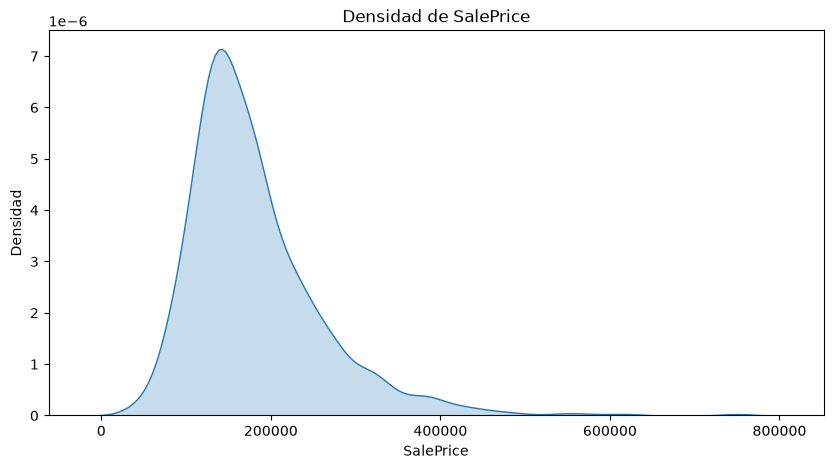

In [4]:
TARGET = "SalePrice"

fig, ax = plt.subplots(figsize=(10, 5))
sns.kdeplot(data=train, x=TARGET, fill=True, ax=ax)
ax.set_title(f"Densidad de {TARGET}")
ax.set_xlabel(TARGET)
ax.set_ylabel("Densidad")
plt.show()

## 4. Clasificación de variables numéricas: discretas y continuas

Las variables numéricas (excepto `Id` y `SalePrice`) se separan según su número de valores únicos: con `MAX_DISCRETE_VALUES` o menos se consideran **discretas** (conteos, escalas de calificación, años o meses de venta) y el resto **continuas**. El umbral puede ajustarse según el análisis.

In [5]:
MAX_DISCRETE_VALUES = 15

num_cols = train.select_dtypes(include="number").columns.drop(["Id", TARGET])
n_unique = train[num_cols].nunique()

discretas = n_unique[n_unique <= MAX_DISCRETE_VALUES].index.tolist()
continuas = n_unique[n_unique > MAX_DISCRETE_VALUES].index.tolist()

print(f"Discretas ({len(discretas)}): {discretas}")
print(f"Continuas ({len(continuas)}): {continuas}")

Discretas (15): ['MSSubClass', 'OverallQual', 'OverallCond', 'BsmtFullBath', 'BsmtHalfBath', 'FullBath', 'HalfBath', 'BedroomAbvGr', 'KitchenAbvGr', 'TotRmsAbvGrd', 'Fireplaces', 'GarageCars', 'PoolArea', 'MoSold', 'YrSold']
Continuas (21): ['LotFrontage', 'LotArea', 'YearBuilt', 'YearRemodAdd', 'MasVnrArea', 'BsmtFinSF1', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', '1stFlrSF', '2ndFlrSF', 'LowQualFinSF', 'GrLivArea', 'GarageYrBlt', 'GarageArea', 'WoodDeckSF', 'OpenPorchSF', 'EnclosedPorch', '3SsnPorch', 'ScreenPorch', 'MiscVal']


## 5. Relación de las variables continuas con `SalePrice`

Diagrama de dispersión de cada variable continua frente a la variable objetivo, con el coeficiente de correlación de Pearson (r) en el título. Permite identificar relaciones lineales, no lineales y valores atípicos.

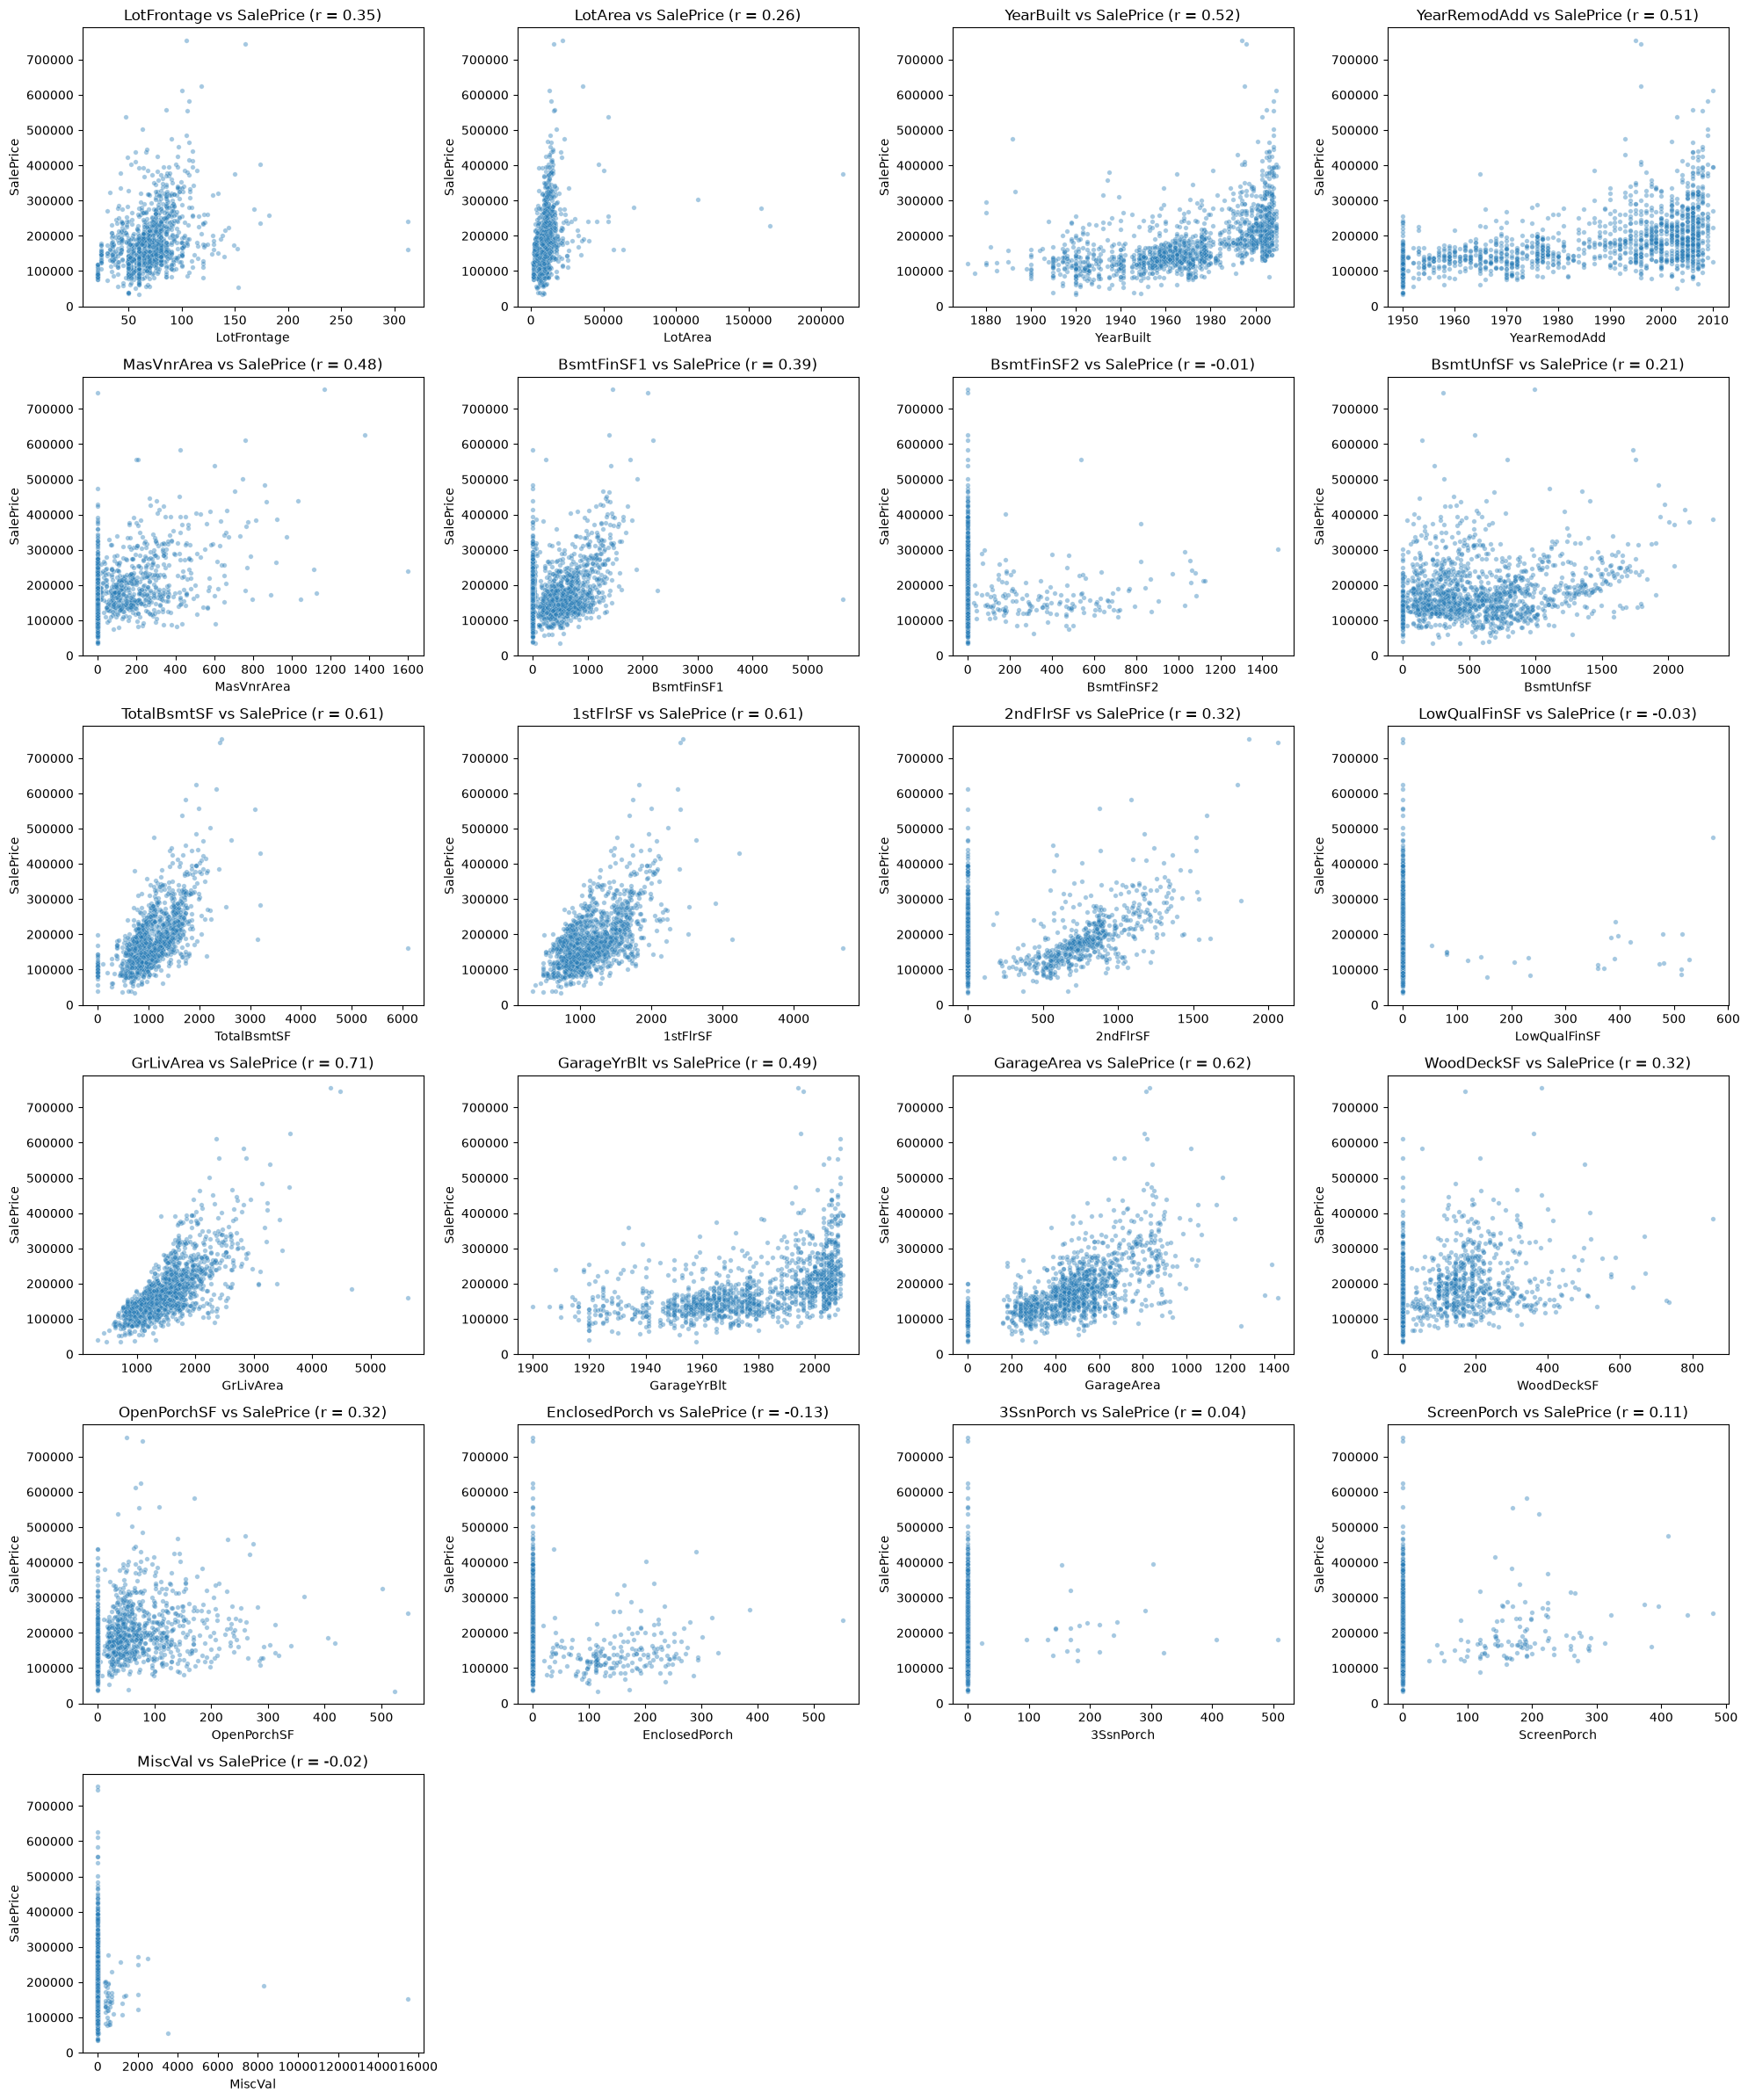

In [6]:
correlations = train[continuas].corrwith(train[TARGET])

n_cols = 4
n_rows = int(np.ceil(len(continuas) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(5 * n_cols, 4 * n_rows))

for ax, col in zip(axes.flat, continuas):
    sns.scatterplot(data=train, x=col, y=TARGET, alpha=0.4, s=15, ax=ax)
    ax.set_title(f"{col} vs {TARGET} (r = {correlations[col]:.2f})")

for ax in axes.flat[len(continuas):]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()

### 5.1 Ranking de correlaciones

Coeficientes de correlación de cada variable continua con `SalePrice`, ordenados de mayor a menor.

In [7]:
corr_df = (
    correlations.sort_values(ascending=False)
    .rename_axis("variable")
    .reset_index(name="correlacion")
)
corr_df

,variable,correlacion
0,GrLivArea,0.708624
1,GarageArea,0.623431
2,TotalBsmtSF,0.613581
3,1stFlrSF,0.605852
4,YearBuilt,0.522897
5,YearRemodAdd,0.507101
6,GarageYrBlt,0.486362
7,MasVnrArea,0.477493
8,BsmtFinSF1,0.386420
9,LotFrontage,0.351799


## 6. Relación de las variables discretas con `SalePrice`

Diagrama de caja de `SalePrice` para cada valor de la variable discreta. Las observaciones individuales se superponen como puntos con dispersión horizontal (*jitter*) para mostrar la cantidad de casos en cada categoría y su distribución.

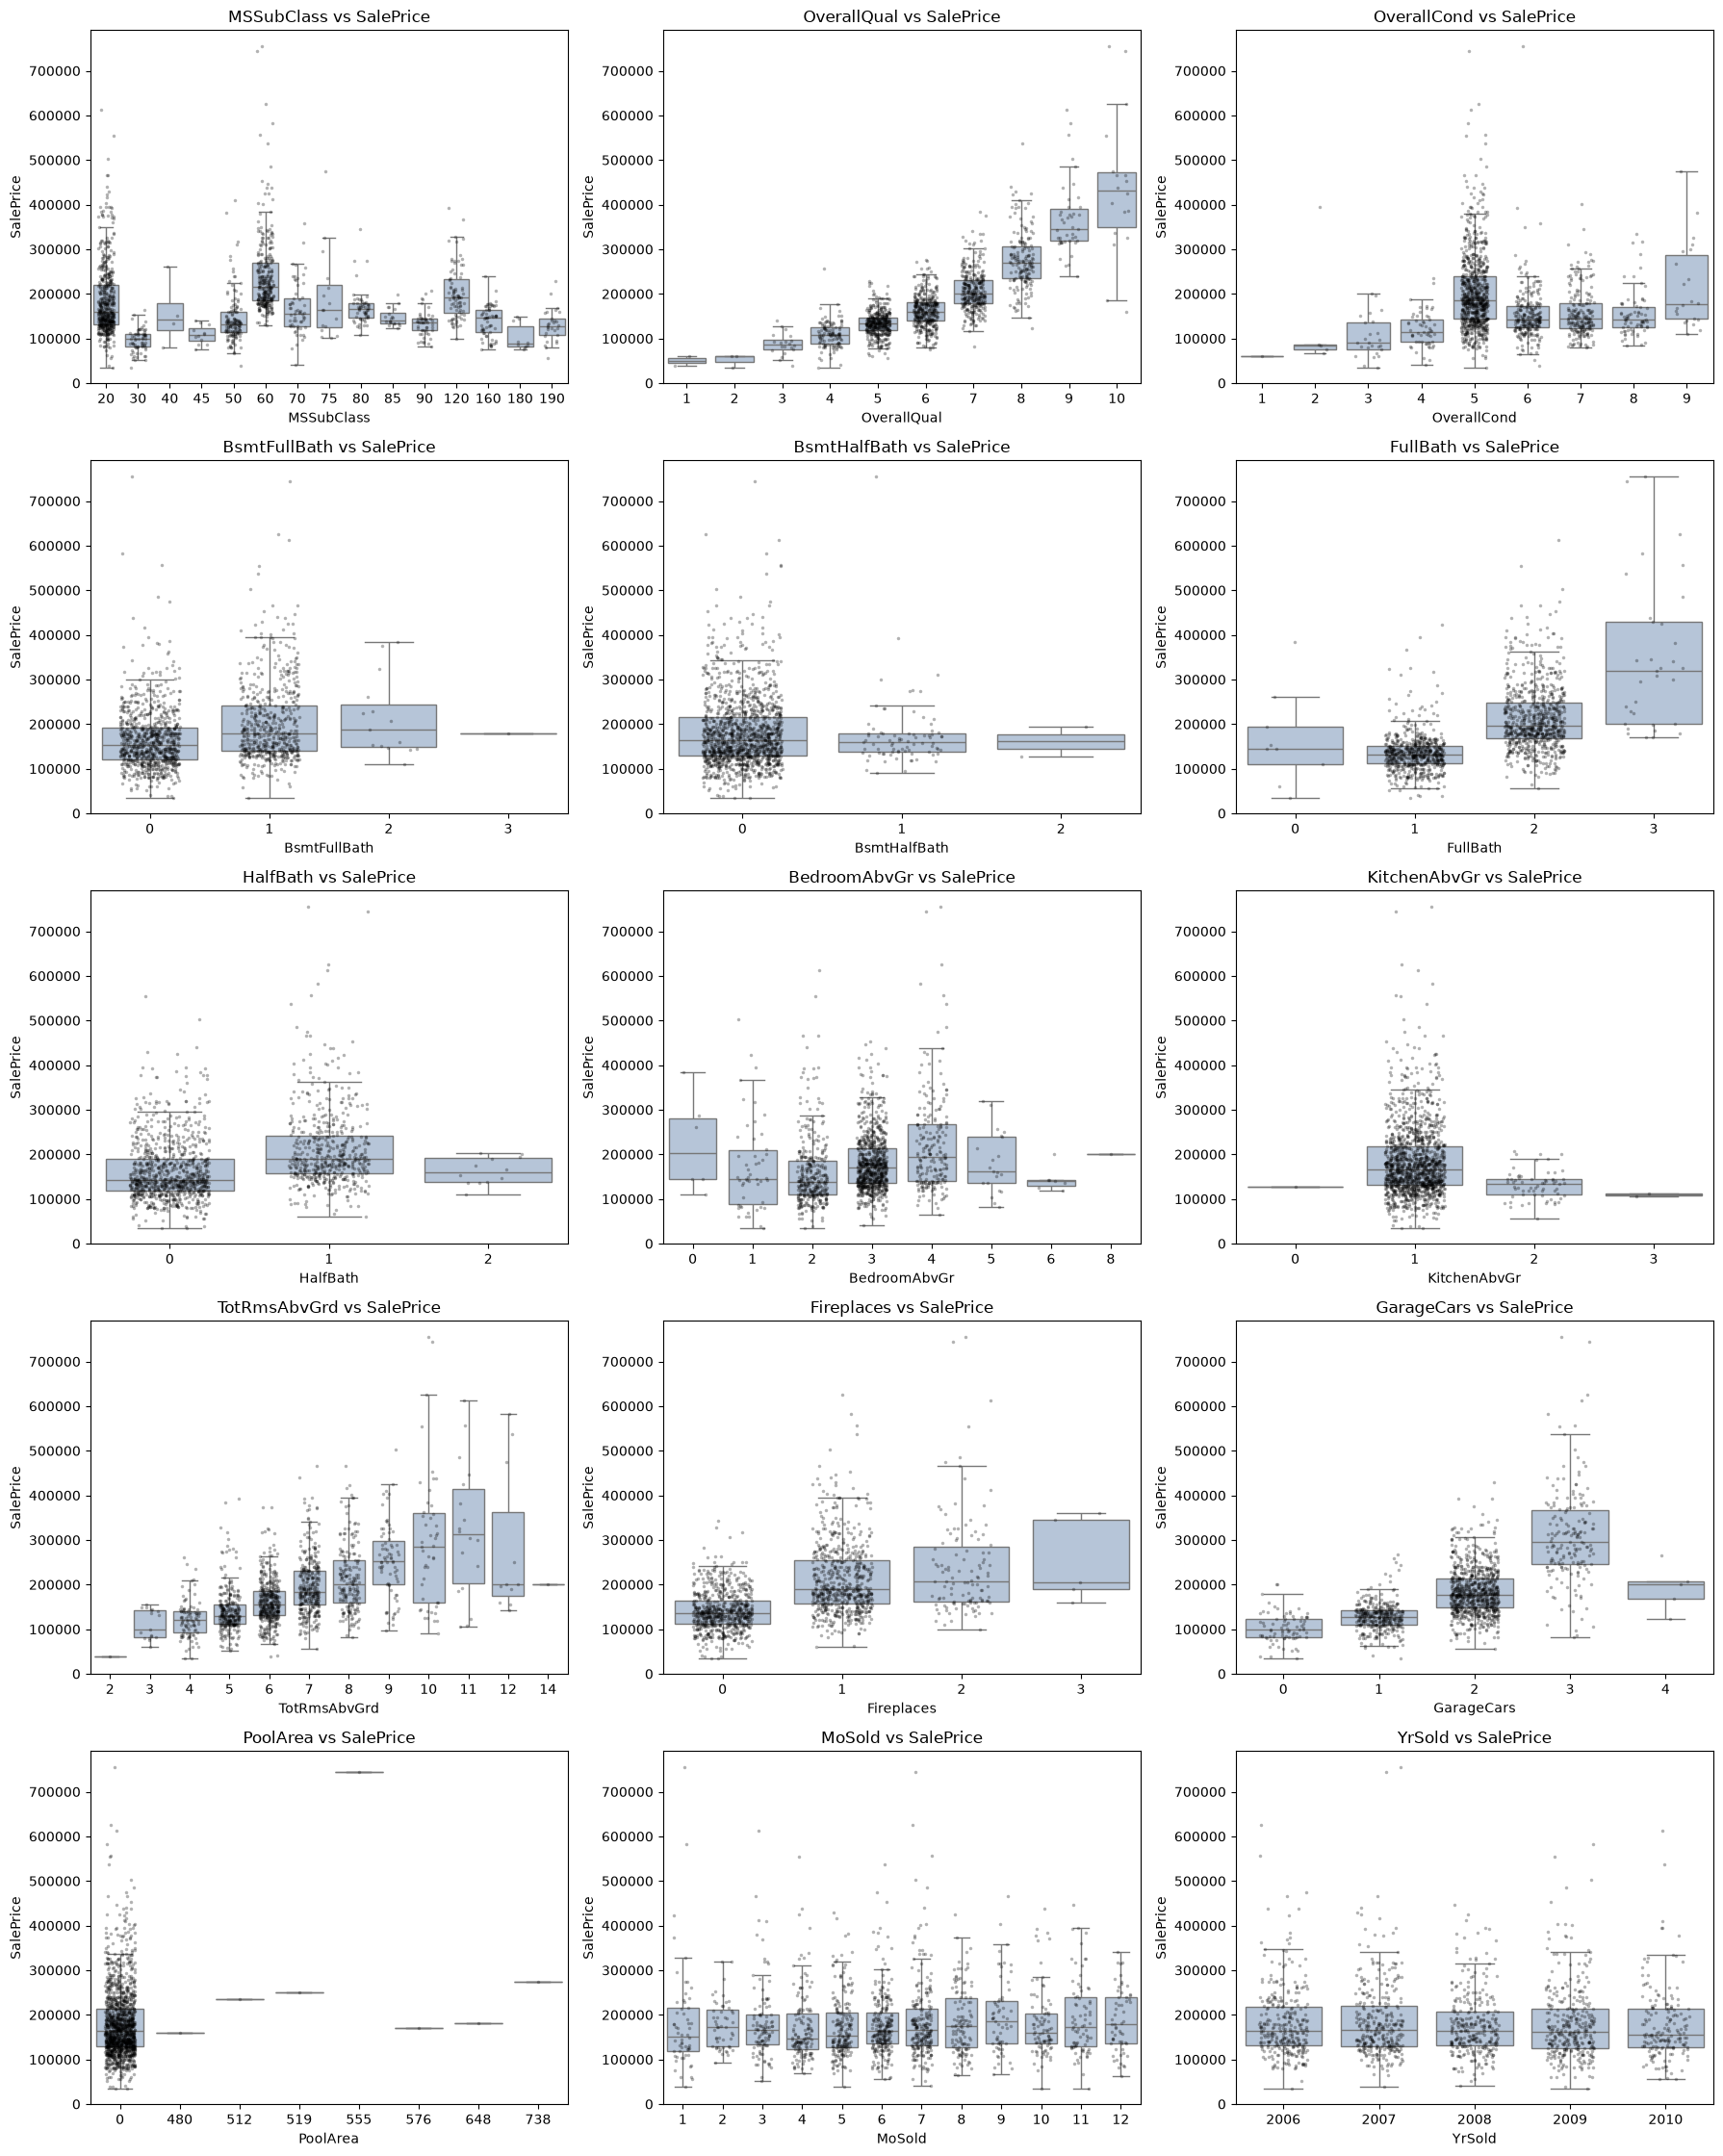

In [8]:
n_cols = 3
n_rows = int(np.ceil(len(discretas) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(6 * n_cols, 4.5 * n_rows))

for ax, col in zip(axes.flat, discretas):
    sns.boxplot(data=train, x=col, y=TARGET, color="lightsteelblue", showfliers=False, ax=ax)
    sns.stripplot(data=train, x=col, y=TARGET, color="black", alpha=0.3, size=2.5, jitter=0.25, ax=ax)
    ax.set_title(f"{col} vs {TARGET}")

for ax in axes.flat[len(discretas):]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()

## 7. Relación de las variables categóricas con `SalePrice`

Diagrama de caja de `SalePrice` para cada categoría, ordenadas por mediana. El título incluye la **razón de correlación (η)**, equivalente a la correlación para una variable categórica frente a una numérica:

$$\eta = \sqrt{\frac{\sum_k n_k (\bar{y}_k - \bar{y})^2}{\sum_i (y_i - \bar{y})^2}}$$

donde $\bar{y}_k$ y $n_k$ son la media y el número de observaciones de la categoría $k$, y $\bar{y}$ la media global. Mide la proporción de la variabilidad de `SalePrice` explicada por las diferencias entre categorías; toma valores entre 0 (sin relación) y 1 (la categoría determina el precio). Los valores faltantes se tratan como la categoría `NA`, ya que en la mayoría de estas variables indican ausencia de la característica.

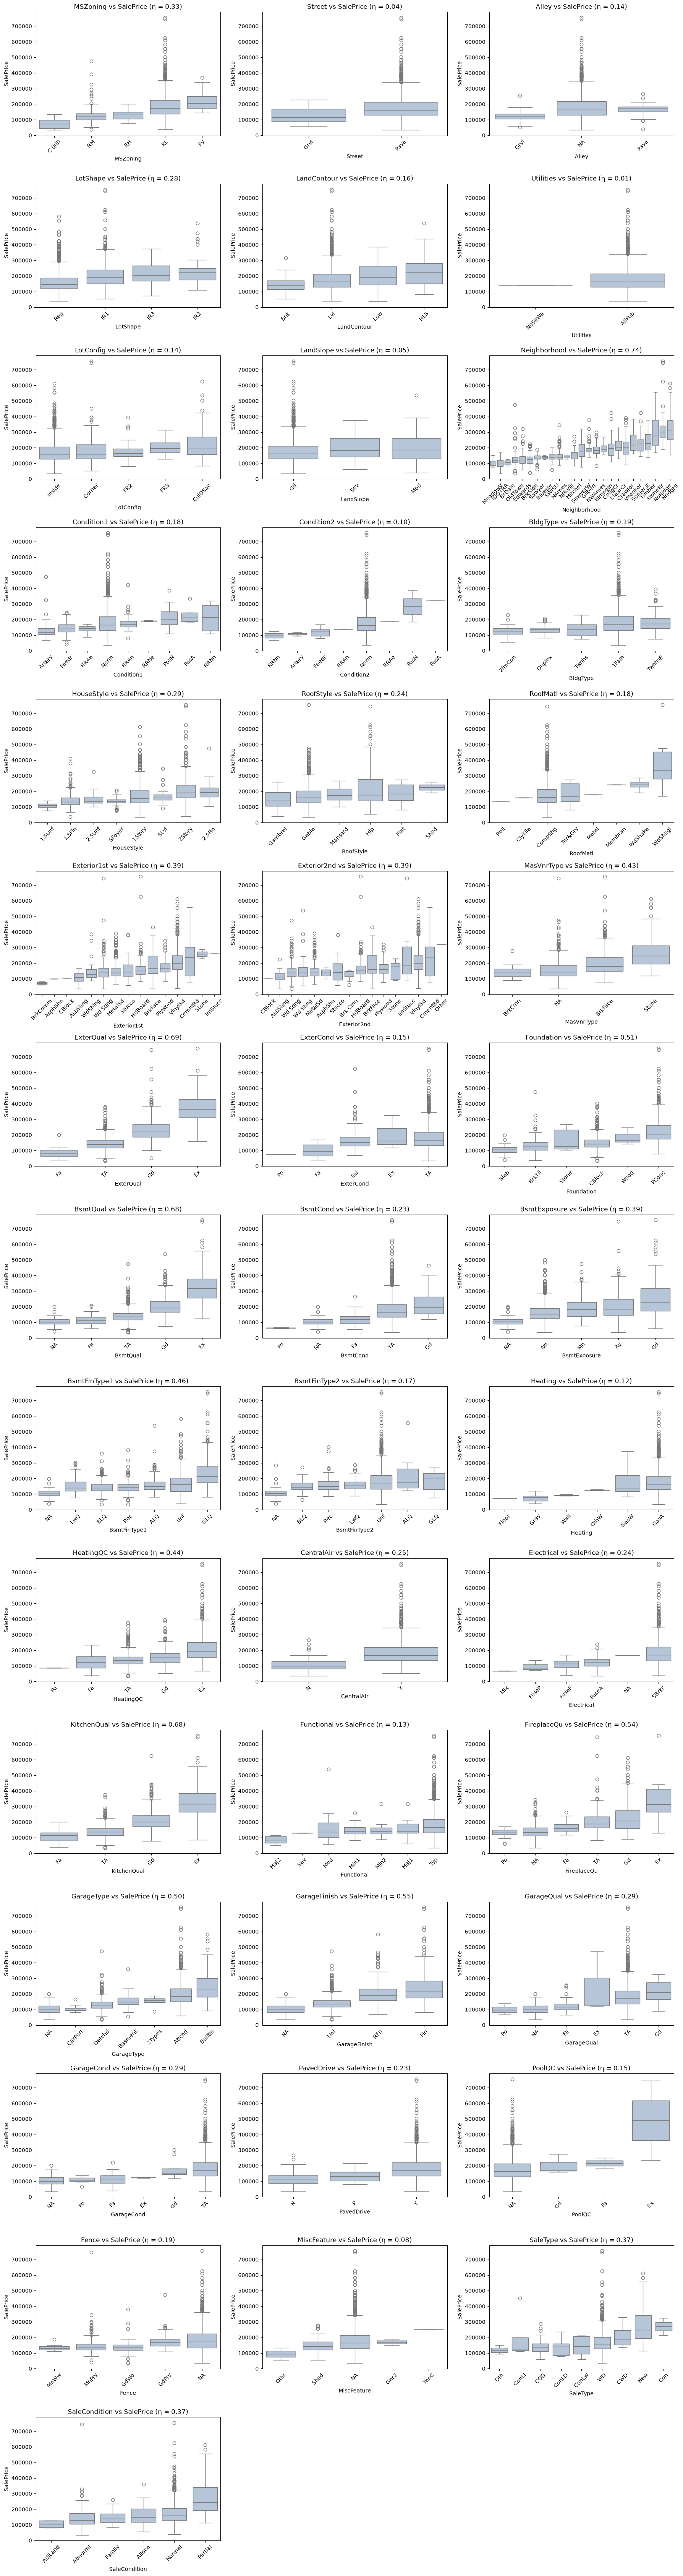

In [9]:
def correlation_ratio(categories, values):
    """Razón de correlación (eta) entre una variable categórica y una numérica."""
    group_means = values.groupby(categories).transform("mean")
    ss_between = ((group_means - values.mean()) ** 2).sum()
    ss_total = ((values - values.mean()) ** 2).sum()
    return np.sqrt(ss_between / ss_total)


categoricas = train.select_dtypes(exclude="number").columns.tolist()
cat_data = train[categoricas].fillna("NA")
eta = {col: correlation_ratio(cat_data[col], train[TARGET]) for col in categoricas}

n_cols = 3
n_rows = int(np.ceil(len(categoricas) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(6 * n_cols, 4.5 * n_rows))

for ax, col in zip(axes.flat, categoricas):
    order = train[TARGET].groupby(cat_data[col]).median().sort_values().index
    sns.boxplot(x=cat_data[col], y=train[TARGET], order=order, color="lightsteelblue", ax=ax)
    ax.set_title(f"{col} vs {TARGET} (η = {eta[col]:.2f})")
    ax.tick_params(axis="x", rotation=45)

for ax in axes.flat[len(categoricas):]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()

### 7.1 Ranking de la razón de correlación

Razón de correlación (η) de cada variable categórica con `SalePrice`, ordenada de mayor a menor.

In [10]:
eta_df = (
    pd.Series(eta)
    .sort_values(ascending=False)
    .rename_axis("variable")
    .reset_index(name="eta")
)
eta_df

,variable,eta
0,Neighborhood,0.738630
1,ExterQual,0.690933
2,BsmtQual,0.681905
3,KitchenQual,0.675721
4,GarageFinish,0.553059
5,FireplaceQu,0.542181
6,Foundation,0.506328
7,GarageType,0.499204
8,BsmtFinType1,0.459141
9,HeatingQC,0.442154


## 8. Selección de features

Se seleccionan las `TOP_N` variables con mayor relación con `SalePrice` en cada grupo:

- **Continuas:** valor absoluto de la correlación de Pearson |r|, ya que una correlación negativa fuerte también es informativa.
- **Discretas:** razón de correlación η. A diferencia de r, no supone una relación lineal ni un orden numérico, lo que es relevante para variables codificadas como `MSSubClass`.
- **Categóricas:** razón de correlación η (sección 7.1).

La unión de los tres grupos conforma `modelo_features`.

In [11]:
TOP_N = 10

eta_discretas = pd.Series({col: correlation_ratio(train[col], train[TARGET]) for col in discretas})

top_continuas = correlations.abs().sort_values(ascending=False).head(TOP_N).index.tolist()
top_discretas = eta_discretas.sort_values(ascending=False).head(TOP_N).index.tolist()
top_categoricas = eta_df["variable"].head(TOP_N).tolist()

modelo_features = top_continuas + top_discretas + top_categoricas

seleccion_df = pd.concat([
    pd.DataFrame({"grupo": "continua", "variable": top_continuas, "metrica": "|r|",
                  "valor": correlations.abs()[top_continuas].values}),
    pd.DataFrame({"grupo": "discreta", "variable": top_discretas, "metrica": "eta",
                  "valor": eta_discretas[top_discretas].values}),
    pd.DataFrame({"grupo": "categorica", "variable": top_categoricas, "metrica": "eta",
                  "valor": eta_df["eta"].head(TOP_N).values}),
], ignore_index=True)

print(f"Total de features seleccionadas: {len(modelo_features)}")
seleccion_df

Total de features seleccionadas: 30


,grupo,variable,metrica,valor
0,continua,GrLivArea,|r|,0.708624
1,continua,GarageArea,|r|,0.623431
2,continua,TotalBsmtSF,|r|,0.613581
3,continua,1stFlrSF,|r|,0.605852
4,continua,YearBuilt,|r|,0.522897
5,continua,YearRemodAdd,|r|,0.507101
6,continua,GarageYrBlt,|r|,0.486362
7,continua,MasVnrArea,|r|,0.477493
8,continua,BsmtFinSF1,|r|,0.386420
9,continua,LotFrontage,|r|,0.351799


### 8.1 Guardar la configuración del pipeline

Se guarda en `pipeline_config.yaml`, en la raíz del proyecto, la configuración necesaria para las siguientes etapas: variable objetivo, ubicación de los datos, features seleccionadas por grupo y la lista final `MODEL_FEATURES`.

In [12]:
import yaml

CONFIG_PATH = Path("../pipeline_config.yaml")

pipeline_config = {
    "TARGET": TARGET,
    "DATA": {
        "RAW_DIR": "data/raw",
        "TRAIN_FILE": TRAIN_FILE,
        "TEST_FILE": TEST_FILE,
    },
    "FEATURES": {
        "CONTINUAS": top_continuas,
        "DISCRETAS": top_discretas,
        "CATEGORICAS": top_categoricas,
    },
    "MODEL_FEATURES": modelo_features,
}

with open(CONFIG_PATH, "w", encoding="utf-8") as f:
    yaml.safe_dump(pipeline_config, f, sort_keys=False, allow_unicode=True)

print(f"Configuración guardada en: {CONFIG_PATH}")

Configuración guardada en: ..\pipeline_config.yaml
